# Exact Green's function and self-energy: the 1D hydrogen atom

iDEA can construct the **exact** one-body Green's function $G(x,x';t)$ and **exact** exchange-correlation self-energy $\Sigma_{xc}(x,x';\omega)$ of an interacting state, from the exact eigenstates of the $(N-1)$- and $(N+1)$-electron systems (the Lehmann representation):

$$G_\sigma(x,x';z) = \sum_k \frac{d_k(x)\,d_k^*(x')}{z-\varepsilon_k},$$

with removal poles $\varepsilon_k = E^N_0 - E^{N-1}_k$ and Dyson orbitals $d_k(x) = \langle\Psi^{N-1}_k|\hat\psi_\sigma(x)|\Psi^N_0\rangle$, and addition poles $\varepsilon_k = E^{N+1}_k - E^N_0$ with $d_k(x) = \langle\Psi^N_0|\hat\psi_\sigma(x)|\Psi^{N+1}_k\rangle$. The self-energy is defined by Dyson's equation,

$$G^{-1}(z) = z - h_0 - v_h - \Sigma_{xc}(z), \qquad \Sigma_{xc}(z) = \Sigma_x + \sum_p \frac{r_p(x)\,r_p^*(x')}{z-\zeta_p},$$

and is also obtained exactly, in pole form. Its static part is the Fock operator of the exact density matrix.

Each sector is diagonalised in its Slater-determinant basis, either completely (`solver='dense'`) or with a block Krylov method seeded by $\hat\psi_\sigma(x)|\Psi\rangle$ and $\hat\psi_\sigma^\dagger(x)|\Psi\rangle$ (`solver='krylov'`), which keeps every sum rule exact. Here we use the simplest example, one electron bound by a softened nucleus, where the exact self-energy must cancel the electron's self-interaction exactly, something approximate self-energies such as *GW* do not do (self-screening).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import iDEA

x = np.linspace(-12, 12, 61)
s = iDEA.system.System(x, -1.0 / (abs(x) + 1.0), iDEA.interactions.softened_interaction(x), electrons="u")
state = iDEA.methods.interacting.solve(s, k=0)
green = iDEA.methods.interacting.green_function(s, state)
print(f"E0 = {state.energy:.8f}, mu = {green.mu:.6f}")
print({key: f"{value:.1e}" for key, value in green.info.items() if key != "sectors"})

iDEA.methods.interacting.solve: solving eigenproblem on CPU...
iDEA.methods.interacting.green_function: adding a spin-up electron, sector dimension 1830...


iDEA.methods.interacting.green_function: adding a spin-down electron, sector dimension 3721...


E0 = -0.51083377, mu = -0.278439
{'rayleigh_residual': '8.8e-15', 'up_completeness_error': '1.1e-15', 'up_first_moment_error': '5.4e-14', 'down_completeness_error': '8.9e-16', 'down_first_moment_error': '5.1e-14', 'galitskii_migdal_error': '2.2e-16'}


The `info` dictionary records the exact sum rules: completeness of the Dyson orbitals, the first moment (the static self-energy equals the Fock operator of the exact density matrix), the Galitskii–Migdal energy and the Rayleigh-quotient residual of the state. All are at machine precision.

For one electron there is a single removal pole, at $E_0 = -I$ (the vacuum has zero energy), with the occupied orbital as its Dyson orbital. The addition poles are the two-electron states: triplets in the up channel and singlets (including the weakly bound H$^-$ ion) in the down channel.

removal pole: [-0.51083377]  E0: -0.5108337683315927


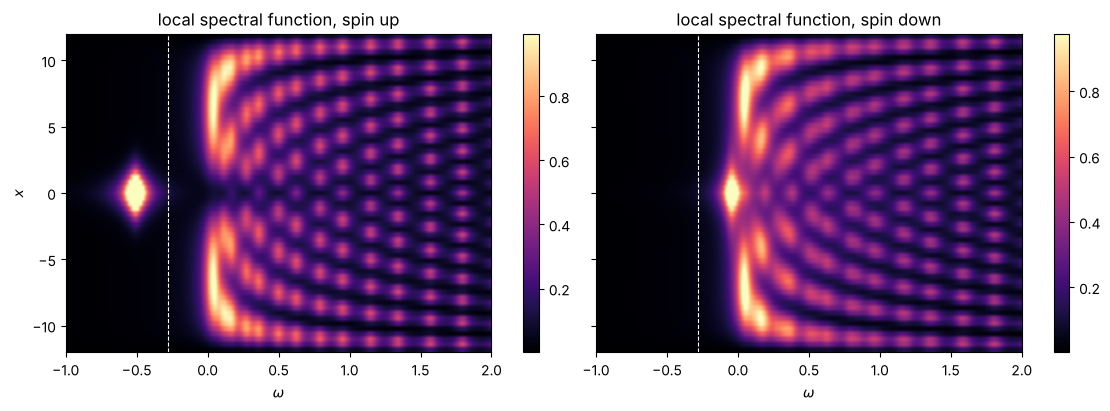

In [2]:
removal = green.up.occupations > 0
print("removal pole:", green.up.energies[removal], " E0:", state.energy)

omega = np.linspace(-1.0, 2.0, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
for ax, spin in zip(axes, ("up", "down")):
    A = iDEA.observables.spectral_function(s, green, omega, eta=0.05, spin=spin, diagonal=True)
    image = ax.imshow(A.T, origin="lower", aspect="auto", extent=[omega[0], omega[-1], x[0], x[-1]], cmap="magma", vmax=np.percentile(A, 99.5))
    ax.axvline(green.mu, color="w", ls="--", lw=0.8)
    ax.set_xlabel(r"$\omega$")
    ax.set_title(f"local spectral function, spin {spin}")
    fig.colorbar(image, ax=ax)
axes[0].set_ylabel("$x$")
plt.show()

## Self-interaction

For one electron, $(v_h + \Sigma_{xc}(z))\,\phi = 0$ for the occupied orbital $\phi$ at every frequency: the exchange part cancels the Hartree potential and the correlation part annihilates $\phi$. Every correlation pole is particle-like (character $+1$).

In [3]:
phi = green.up.orbitals[:, removal][:, 0]
sigma_x = iDEA.observables.self_energy(s, green, part="x")
nu = np.array([0.0, 0.5, 2.0])
sigma_c = iDEA.observables.self_energy(s, green, nu=nu, part="c")
print("|(v_h + Sigma_x) phi| =", np.linalg.norm(green.v_h * phi + sigma_x @ phi * s.dx))
print("|Sigma_c(i nu) phi|   =", [np.linalg.norm(S @ phi * s.dx) for S in sigma_c])
print("self-energy pole characters:", np.unique(np.round(green.up.sigma_character, 12)), np.unique(np.round(green.down.sigma_character, 12)))

|(v_h + Sigma_x) phi| = 2.4582221771313854e-14
|Sigma_c(i nu) phi|   = [np.float64(3.3723047451168446e-17), np.float64(3.082615998998228e-17), np.float64(1.941168393230866e-17)]
self-energy pole characters: [1.] [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Comparison with *GW*

The same quantities from G$_0$W$_0$, GW$_0$ and self-consistent *GW* (`iDEA.methods.mbpt`) on the imaginary axis. Each method's occupied orbital is used. *GW* leaves a self-screening residual and over-binds the electron.

G0W0  E = -0.517064   (exact -0.510834)


GW0   E = -0.516250   (exact -0.510834)


GW    E = -0.516269   (exact -0.510834)


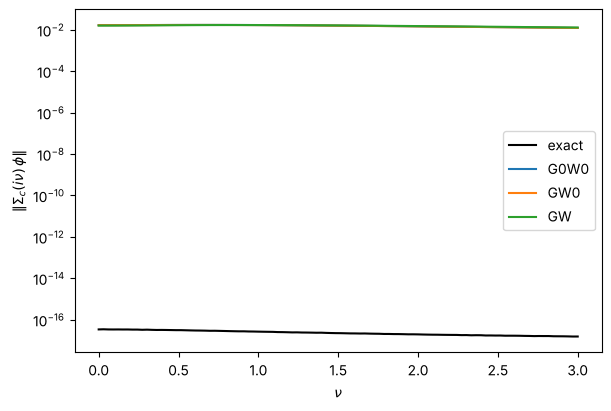

In [4]:
nu = np.linspace(0.0, 3.0, 100)
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
exact = [np.linalg.norm(S @ phi) * s.dx for S in iDEA.observables.self_energy(s, green, nu=nu, part="c")]
ax.semilogy(nu, np.maximum(exact, 1e-18), "k-", label="exact")
gw = {}
for mode in ("G0W0", "GW0", "GW"):
    gw[mode] = iDEA.methods.mbpt.solve(s, mode=mode, silent=True)
    phi_gw = gw[mode].up.orbitals[:, gw[mode].up.occupations > 0][:, 0]
    residual = [np.linalg.norm(S @ phi_gw) * s.dx for S in iDEA.observables.self_energy(s, gw[mode], nu=nu, part="c")]
    ax.semilogy(nu, residual, label=mode)
    print(f"{mode:5s} E = {gw[mode].energy:.6f}   (exact {state.energy:.6f})")
ax.set_xlabel(r"$\nu$")
ax.set_ylabel(r"$\Vert\Sigma_c(i\nu)\,\phi\Vert$")
ax.legend()
plt.show()

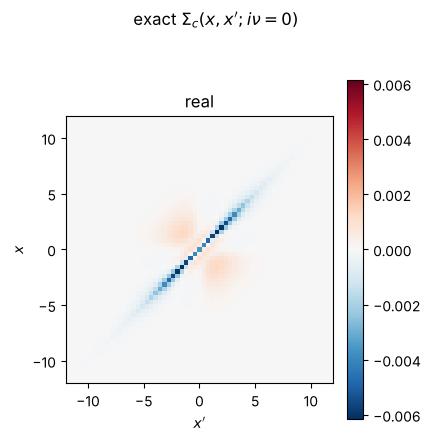

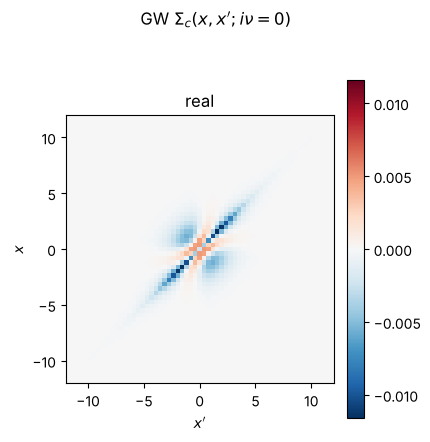

In [5]:
fig = iDEA.plotting.plot_two_point(x, iDEA.observables.self_energy(s, green, nu=np.array([0.0]), part="c")[0], parts=("real",), title=r"exact $\Sigma_c(x,x';i\nu=0)$")
display(fig)
fig = iDEA.plotting.plot_two_point(x, iDEA.observables.self_energy(s, gw["GW"], nu=np.array([0.0]), part="c")[0], parts=("real",), title=r"GW $\Sigma_c(x,x';i\nu=0)$")
display(fig)

## Snapshots and videos

`iDEA.plotting.plot_two_point` draws a snapshot of any two-point quantity, and `iDEA.plotting.animate` (with the wrappers `animate_green_function` and `animate_self_energy`) animates it over real time $t$, real frequency $\omega$ or imaginary frequency $\nu$, saving `.mp4` (requires ffmpeg) or `.gif` files. In a notebook the returned animation can be shown inline with `IPython.display.HTML(animation.to_jshtml())`.

On the real-time axis the Green's function of a point-like added electron contains every grid energy, which dominates the picture; the `cutoff` argument applies a smooth energy filter about $\mu$ to band-limit such videos (the result is then no longer exact).

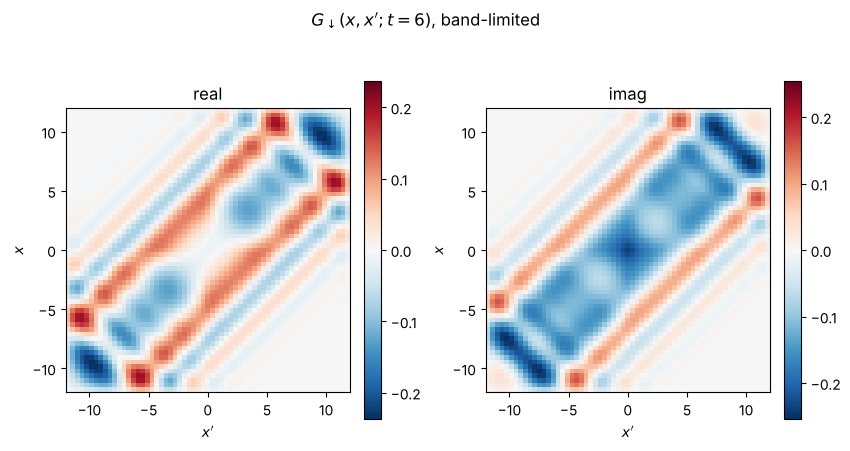

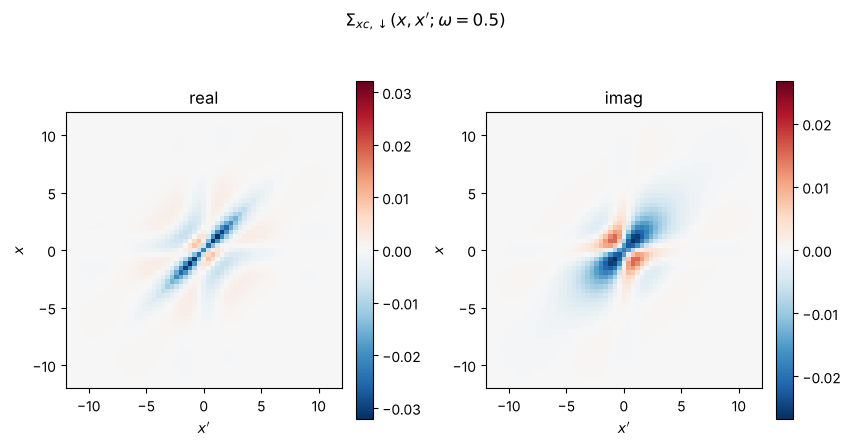

In [6]:
t = np.array([6.0])
G = iDEA.observables.green_function(s, green, t=t, spin="down", cutoff=1.0)[0]
display(iDEA.plotting.plot_two_point(x, G, title=r"$G_\downarrow(x,x';t=6)$, band-limited"))
sigma = iDEA.observables.self_energy(s, green, omega=np.array([0.5]), spin="down")[0]
display(iDEA.plotting.plot_two_point(x, sigma, title=r"$\Sigma_{xc,\downarrow}(x,x';\omega=0.5)$"))

In [7]:
# Videos are written to files (set SAVE = True to render them; this takes a minute or two).
SAVE = False
if SAVE:
    iDEA.plotting.animate_green_function(s, green, t=np.linspace(0, 30, 150), spin="down", cutoff=1.0, demodulate=True, file_name="G_down_t.mp4")
    iDEA.plotting.animate_self_energy(s, green, omega=np.linspace(-1, 2, 150), spin="down", file_name="Sigma_xc_down_omega.mp4")
    iDEA.plotting.animate_self_energy(s, green, t=np.linspace(0, 30, 150), spin="down", cutoff=1.0, file_name="Sigma_c_down_t.mp4")

For production-quality grids, and the full set of videos and figures, see `tutorial/green_function_hydrogen.py` (with `--gpu` to diagonalise the sectors on a GPU).